---
title: Tracks widget
---

In [ ]:
import numpy as np
import pandas as pd
from time import sleep
import pyarrow.parquet as pq
from pathlib import Path
import pickle
from collections import OrderedDict, defaultdict
from geneinfo.widget import Tracks
from geneinfo.coords import chromosome_lengths, gene_coords, gene_labels
from geneinfo.genelist import GeneList as glist
from geneinfo.genelist import GeneListCollection
import crossrepo
import vscodenb
import seaborn as sns
sns.set_palette('tab10')

## Widget Controls

**Toolbar (left-to-right):**
- **Chromosome dropdown** — switch chromosome.
- **Position box** — type a coordinate (`50000000`) or range (`chr1:1e6-2e6`) and press Enter. Invalid input flashes the box red with a tooltip hint.
- **＋ / −** — zoom in / out (cursor-anchored in the plot).
- **«  ‹  ›  »** — pan left / right by 90 % / 50 % of the view.
- **⌂** — reset to the full chromosome.
- **⟲** — recompute heatmap(s) at the current view for higher resolution. Shows a spinner while rebin is in flight. *(heatmap tracks only)*
- **◱** — restore the whole-chromosome heatmap view. *(heatmap tracks only)*
- **A** — show all gene labels when fewer than 100 genes are visible. *(gene tracks only)*
- **⧉** — snapshot the current view. Flashes **✓** if copied to the clipboard, **⇓** if downloaded as a PNG fallback, **!** on failure.
- **?** — help popover listing mouse, keyboard, and toolbar controls. `Esc` or click-outside to dismiss.
- **▬ segments / ▒ density** badge — LOD indicator.

**Mouse:**
- **Drag** on the plot to pan.
- **Scroll wheel** to zoom (anchored on the cursor's genomic position).
- **Double-click** to zoom in 2× centred on the click.
- **Hover** for a context-sensitive tooltip (gene name, y-value, group, individual, ...).

**Keyboard (when the widget has focus):**
- **← / →** — pan by 15 % of the current view.
- **+ / =** — zoom in 1.5×.  **−** — zoom out 1.5×.

**Python:**
- `viewer.zoom_to(chrom, center=..., window=...)` — jump programmatically. Raises `KeyError` for unknown chromosomes.
- `viewer.set_viewport(chrom, start, end)` — set the viewport directly; clamps out-of-range start/end, raises `KeyError` for unknown chromosomes.
- `viewer.viewport` — read the current `{chrom, start, end}` (updates on pan/zoom settle).
- `viewer.remove_track(name_or_index)` / `viewer.clear_tracks()` — remove tracks in place.
- `viewer.zoom_speed = 1.02` — tune wheel-zoom sensitivity.

Documentation: https://munch-group.org/geneinfo/pages/tracks_widget.html

## Dummy quantitative data

In [ ]:
sheet = GeneListCollection(google_sheet='1JSjSLuto3jqdEnnG7JqzeC_1pUZw76n7XueVAYrUOpk')
hybrid_diff_exp_genes = sheet.get('hybridDEG')

def gene_view(name, span=1000000):
    chrom, start, end, _ = gene_coords(name, assembly='hg38')[0]
    return dict(chrom=chrom, center=(start+end)/2, window=span)

def gene_positions(names):
    positions = defaultdict(list)
    for chrom, pos, _ in gene_labels(names, assembly='hg38'):
        positions[chrom].append(pos)
    return positions

def gene_spans(names):
    return pd.DataFrame().from_records(gene_coords(names, assembly='hg38'), columns=['chrom', 'start', 'end', 'name'])


## ECH regions

In [ ]:
ECH_regions = {'chrX': [
  (19781882, 19881882),  (21181882, 21281882),
  (36181883, 36381885), (37440747, 37840747),
  (50057375, 50057403), (51057154, 51657066),
  (54173567, 54373567), (65480120, 65680139),
  (73780165, 74080165), (74680165, 75080165),
  (77644510, 77944503), (99445002, 99545002),
  (111456772, 111856772), (114765448, 115065437),
  (127866021, 127966021), (130566026, 130966026),
  (132165972, 132465972), (133465972, 133765973),
  (154771725, 155171725)]}

gene_pos = gene_positions(hybrid_diff_exp_genes)

## Read in archaic segments

```{.python}
meta = pq.ParquetFile('/Users/kmt/davide_segments_v2/dims/metadata.parquet').read().to_pandas()
meta.reg.unique()

# # subset_regs = ['AFR', 'EUR', 'EAS', 'SAS', 'MID', 'OCE', 'AMR']
# subset_regs = ['EUR', 'EAS', 'OCE']
# subset_meta = meta[(meta['sex'] == 'F') & meta['reg'].isin(subset_regs)].groupby('reg').head(1000)

subset_meta = meta[meta['reg'].isin(['EUR', 'EAS', 'OCE'])].groupby('reg').head(50)

frames = []
for ind in subset_meta['ind']:
    fp = Path(f'/Users/kmt/davide_segments_v2/fragments/phase_state=phased/ind={ind}/0.parquet')
    if fp.exists() and fp.stat().st_size:
        data = pq.ParquetFile(fp).read()
        frames.append(pq.ParquetFile(fp).read().to_pandas())
segments = pd.concat(frames, ignore_index=True)
segments['chrom'] = 'chr' + segments['chrom'].astype(str)
segments = segments.merge(meta[['ind', 'reg', 'pop', 'sex']], on='ind', how='left')

|
print(f'{len(segments):,} segments from {segments["ind"].nunique()} individuals')
print(f'Mean length: {(segments["end"] - segments["start"]).mean():,.0f} bp')
print(f'Regions: {dict(segments.groupby("reg")["ind"].nunique())}')
print(f'Ancestries: {sorted(segments["ancestry"].unique())}')

region_colors={'AFR': "#d80019", 'EUR': "#0067cf", 'SAS': "#7e00bd", 'EAS': "#00a75f", 'MID': "#c20098", 'OCE': "#d19300", 'AMR': "#7e4e00"}
ancestry_colors={'Altai': 'green', 'Vindija': 'orange', 'Chagyrskaya': 'blue', 'AmbigNean': 'purple', 'Denisova': 'red', 'nonDAVC': 'gray'}
```

In [ ]:
# ! scp kmt@login.genome.au.dk:~/GenerationInterval/people/kmt/segments.parquet .

In [ ]:
segments = pd.read_parquet('segments.parquet')
print(f'{len(segments):,} segments from {segments["ind"].nunique()} individuals')


## Crossrepo tracks

In [ ]:
crossrepo.active_config()

In [ ]:
#crossrepo.refresh()

In [ ]:
df = crossrepo.list()
df.loc[df.repo != 'munch-group/long-read-lof']

In [ ]:
tracks = Tracks(assembly='hg38')

In [ ]:
tracks = Tracks(assembly='hg38')
# Same but also rank using a `group_by`:
tracks.add_heatmap_track(segments.loc[segments.reg.isin(['EUR', 'EAS', 'OCE'])], "Ancestry", individual_col="ind", value_col="min_dist_anc", group_by="reg").legend('Ancestry')

### Primate ILS

In [ ]:
df = pd.read_hdf(
    crossrepo.get(
        'munch-group/primate-ils', 
        'results/ils_data.h5',
        version="5f99d85b847305c87628d42e7592027bbd6937fe"        
        )
    )
df['chrom'] = ['chr' + x for x in df.chrom]
df['pos'] = (df.start + df.end) / 2
ils_data = df
ils_data

### X sperm chrX A/B compartments

A/B compartment 50kb windows:

In [ ]:
x_sperm_10kb = pd.read_csv(
    crossrepo.get(
        'munch-group/hic-xy-sperm',
        'results/sperm_X_chrX.eigs.10000.cis.vecs.tsv',
        version="2b6a1b8e9ffdbeb253b11efebe333b433f540428"
        ), sep='\t'
)
x_sperm_10kb.head()    

In [ ]:
x_sperm_50kb = pd.read_csv(
    crossrepo.get(
        'munch-group/hic-xy-sperm',
        'results/sperm_X_chrX.eigs.50000.cis.vecs.tsv',
        version="2b6a1b8e9ffdbeb253b11efebe333b433f540428"
        ), sep='\t'
)
x_sperm_50kb.head()    

In [ ]:
x_sperm_100kb = pd.read_csv(
    crossrepo.get(
        'munch-group/hic-xy-sperm',
        'results/sperm_X_chrX.eigs.100000.cis.vecs.tsv',
        version="2b6a1b8e9ffdbeb253b11efebe333b433f540428"
        ), sep='\t'
)
x_sperm_100kb.head()   

### X/Y sperm A/B compartments

A/B compartment 50kb windows:

In [ ]:
xy_sperm_50kb = pd.read_csv(
    crossrepo.get(
        'munch-group/hic-xy-sperm', 
        'results/segments_50000.csv',
        version="ed09883ae116717b6244445e16491b02fc9a4c22"
        )
    )
xy_sperm_50kb.head()

A/B compartment 100kb windows:

In [ ]:
x_sperm_100kb = pd.read_csv(
    crossrepo.get(
        'munch-group/hic-xy-sperm',
        'results/sperm_X_chrX.eigs.100000.cis.vecs.tsv',
        version="2b6a1b8e9ffdbeb253b11efebe333b433f540428"
        ), sep='\t'
)
x_sperm_100kb.head()    

### CTCF sites

In [ ]:
df = pd.read_parquet(
    crossrepo.get(
        'munch-group/CTCF-inversion-data', 
        'results/ctcf_sites_hg38.parquet',
        version="04e2704372e88e7eb6c909ebfdce4303dee065c3"
        )
    )
df['pos'] = df.summit
ctcf_sites_hg38 = df
ctcf_sites_hg38.head()

In [ ]:
df = pd.read_csv(
    crossrepo.get(
        'munch-group/CTCF-inversion-data', 
        'results/ape_inversions_polarized.tsv',
        version="04e2704372e88e7eb6c909ebfdce4303dee065c3"
        ), sep='\t'
    )
ape_inversions_polarized = df.replace('?', np.nan)
ape_inversions_polarized.head()

### Chromatin loops

Medium loops:

In [ ]:
df = pd.read_csv(
    crossrepo.get(
        'munch-group/chromatin-structure', 
        'results/chrX_medium_loops_lifted.csv',
        version="2b291c7aa87323d3ab70312061badc95bfcfc996"
        )
    )
df = df.loc[df.chr1 == df.chr2]
df['pos1']  = df.x_hg38
df['pos2']  = df.y_hg38
df['chrom'] = [f'chr{x}' for x in df.chr1]
chrX_medium_loops_lifted = df
chrX_medium_loops_lifted.head()

Super-loops:

In [ ]:
df = pd.read_csv(
    crossrepo.get(
        'munch-group/chromatin-structure', 
        'results/chrX_superloops.csv',
        version="2b291c7aa87323d3ab70312061badc95bfcfc996" 
        )
    )
df = df.loc[df.chr1 == df.chr2]
df['pos1']  = df.x_hg38
df['pos2']  = df.y_hg38
df['chrom'] = [f'chr{x}' for x in df.chr1]
chrX_superloops = df
chrX_superloops.head()

### Relate 1000 genomes p-values

In [ ]:
# filters = [
#     ('pos', '>=', 892733), 
#     ('pos', '<', 901516),
#     ('pop', '==', "ACB"),
#     ('chrom', '==', "chrX"),
# ]
# pd.read_parquet(path, filters=filters)

relate_snps_p_vals = pd.read_parquet(
    crossrepo.get(
        'munch-group/relate1Kgenomes', 
        'results/relate_snps_p_vals.parquet',
        version="f2a7042fde239562518974d7b29a61fe94910cf5"
        )
    )
relate_snps_p_vals['pval'] = -relate_snps_p_vals.p_two_alleles
relate_snps_p_vals.head()

### Emma's chrX inversions

In [ ]:
# df = pd.read_csv('emmas_chrX_inversions.tsv', sep='\t')
# df['start'] = df.ref_start
# df['end'] = df.ref_end
# df['move'] = df.tar_end - df.ref_start
# df = df.loc[df.ref_species == 'Homo_sapiens']
# df['chrom'] = 'chrX'
# emmas_chrX_inversions = df.sort_values('start').reset_index()
emmas_chrX_inversions = pd.read_csv('emmas_inversions_lifted_to_hg38.tsv', sep='\t')
emmas_chrX_inversions

In [ ]:
#emmas_chrX_inversions[['chrom', 'start', 'end']].to_csv('tmp.tsv', sep='\t', index=False)

### Variant ages

In [ ]:
min_age = 10e3
filters = [['age_mode', '>', min_age]]
df = pd.read_parquet(
    crossrepo.get(
        'munch-group/atlas-variant-ages', 
        'results/atlas_variant_ages.parquet',
        version="6e6fb1c8ba14f9d4a7c936cc1fb95c78eec7ddf4"
        ), engine="pyarrow", filters=filters
    )
atlas_variant_ages = df
atlas_variant_ages['chrom'] = [f'chr{x}' for x in atlas_variant_ages.chrom]
atlas_variant_ages['age_mode_years'] = atlas_variant_ages.age_mode * 30
atlas_variant_ages.head()

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.hist(atlas_variant_ages.loc[atlas_variant_ages.age_mode_years > 6e4, 'age_mode_years'], bins=200)
ax.set_xlim((0, 1500000)) ;

## ChrX Tracks

In [ ]:
tracks = Tracks(assembly='hg38')
tracks.zoom_to('chrX') ;

Chromatin medium loops:

In [ ]:
# tracks.add_arc_track(chrX_medium_loops_lifted, 'Loops', height=90, arc_height=30, alpha=0.85, line_width=1.8) ;

Chromatin chrX super-loops:

In [ ]:
tracks.add_arc_track(chrX_superloops, 'Superloops', group_by='species', height=90, arc_height=60, alpha=0.85, line_width=1.8) ;

Sperm A/B compartments:

In [ ]:
tracks.add_fill_track(x_sperm_50kb, 'X sperm 50kb', x='start', y='E1', step='post', height=120, tip_fmt=False, zoom_windows=(512, 2048, 8192)) ;
# tracks.add_fill_track(x_sperm_10kb, 'X sperm 10kb', x='start', y='E1', step='post', height=120, tip_fmt=False) ;
# tracks.add_fill_track(x_sperm_100kb, 'X sperm 100kb', x='start', y='E1', step='post', height=120, tip_fmt=False, zoom_windows=(512, 2048, 8192)) ;

Autosome X/Y sperm A/B compartments:

In [ ]:
# tracks.add_fill_track(xy_sperm_50kb, 'X sperm', x='start', y='E1_sperm_X', step='post', height=100, tip_fmt=False)
# tracks.add_fill_track(xy_sperm_50kb, 'Y sperm', x='start', y='E1_sperm_Y', step='post', height=100, tip_fmt=False)

In [ ]:
tracks.add_fill_track(xy_sperm_50kb.melt(id_vars=['chrom', 'start'], value_vars=['E1_sperm_X', 'E1_sperm_Y']), 'E1', x='start', y='value', step='post', group_by='variable', alpha=0.5, height=150, tip_fmt=False) ;

CTCF sites:

In [ ]:
tracks.add_segment_track(ctcf_sites_hg38, "CTCF sites") ;

Variant ages:

In [ ]:
tracks.add_point_track(atlas_variant_ages, 'Variant age', x='pos', y='age_mode_years',  height=200, zoom_windows=(2048, 4086, 8192)) ; #, y_scale='log') ;

ILS:

In [ ]:
# tracks.add_histogram_track(ils_data, 'ILS hist', x='pos', y='propils_qnorm', group_by='names', stack=True, height=300, tip_fmt=False) ;
# # tracks.add_heatmap_track(ils_data, "Prop ILS", group_by='names', height=300, value_col='propils_qnorm', zoom_windows='10kb') ;# , '1.5Mb', '500')(512, 2048, 8192)) ;
# # tracks.add_heatmap_track(ils_data, "ILS skew", group_by='names', height=300, value_col='ilsskew_qnorm') ;

Archaic admixture:

In [ ]:
# ancestry_colors={'Altai': 'green', 'Vindija': 'orange', 'Chagyrskaya': 'blue', 'AmbigNean': 'purple', 'Denisova': 'red', 'nonDAVC': 'gray'}
# segm = segments.loc[segments.reg.isin(['EUR', 'EAS', 'OCE'])]
# tracks.add_segment_track(segm, 'Archaic prop', group_by='ancestry', individual_col='ind', height=80, color_map=ancestry_colors, tip_fmt=False, stack=True, zoom_windows=(512, 2048, 8192)) ;
# tracks.add_heatmap_track(segm, "Archaic segm", individual_col="ind", value_col="min_dist_anc", group_by="reg", color_map=ancestry_colors, tip_fmt=False) ; #, zoom_windows=8192) ;

Relate:

In [ ]:
# tracks.add_point_track(relate_snps_p_vals, 'Relate', x='pos', y='pval',  height=200) ;

In [ ]:
# tracks.legend("Prop ILS", "Archaic")
#tracks.legend("Archaic segm")
tracks.zoom_speed = 1.03
tracks.added_tracks()

In [ ]:
tracks


In [ ]:
tracks.clear_spans() ;
tracks.add_spans(ECH_regions, color='green', alpha=0.2, edgecolor='green', edgewidth=1.0) ;
# tracks.add_spans(gene_spans(sheet.get('cDEG')), color='orange', alpha=0.3)
# tracks.add_spans(gene_spans(sheet.get('hybridDEG')), color='orange', alpha=0.4)
tracks.add_spans(emmas_chrX_inversions, color='red', alpha=0.2, edgecolor='red', edgewidth=1.0) ;

In [ ]:
colors = dict(
    highlight_fill_color    = "#e03a4e",                  
    highlight_spine_color   = "#d80ce6",                                          
    highlight_outline_color = "#000000",                                          
    highlight_label_color   = "#169f4a",                                          
    highlight_halo_color    = "#FF990053",    
)
highlight_kwargs = dict(
    highlight={                                                                   
        'outline':    sheet.get('hybridDEG'),
        'stroke':   sheet.get('accel_reg_simiiformes_br'),
        'color':      sheet.get('circRNA'),
        'halo':     sheet.get('nDEG'),
        'bold':      sheet.get('hum_nean_admix'),
        'italic':    sheet.get('ari_nonPUR'),
        'underline': sheet.get('expr_mod_xi_copynr'),
        'fill':      sheet.get('xi_escape'),
    }, 
    **colors
)
if 'Genes' in tracks.added_tracks(): tracks.remove_track('Genes')

tracks.add_gene_track(height = 100, **highlight_kwargs).zoom_to('chrX') ;

In [ ]:
from time import sleep
for tup in emmas_chrX_inversions.itertuples():
    tracks.zoom_to(tup.chrom, tup.start-1e5, tup.end+1e5)
    input()


@SYN1,CXXC1P1,SHROOM4,NUDT10,EZHIP,WNK3,INGX,TAF1,NXF2B,DOCK11,CCDC160,F9,LOC728660,FMR1,FMR1NB,VMA21,MAGE3ADT,DUSP9,PNCK,SLC6AB,BCAP31
SYN1, CXXC1P1, SHROOM4, NUDT10, EZHIP, WNK3, INGX, TAF1, NXF2B, DOCK11, CCDC160, F9, LOC728660, FMR1, FMR1NB, VMA21, MAGE3ADT, DUSP9, PNCK, SLC6AB, BCAP31

Genes overlapping Emmas inversions (bold if some exons in inversions):

- **ANOS1**
- **SYN1**
- **CXXC1P1**
- SHROOM4
- NUDT10, EZHIP
- **WNK3**
- INGX, **TAF1** (right next to OGT)
- **NXF2B** (3 inversions very close to NXF2 and overlaps the TXP11X cluster of multicopy genes)
- left of TMSB15A   
- **DOCK11**    
- CCDC160 (200kb left of PHF6)
- **F9** (one inv), LOC728660 (two inversions) The ATP11C gene is right between the two genes
- **FMR1NB** (A lot of inversions on and around FMR1 and FMR1NB)
- VMA21
- MAGE3ADT
- DUSP9, PNCK, SLC6AB, **BCAP31**

In [ ]:
from geneinfo.information import gene_info
gene_info('NBDY')

In [ ]:
gene_info(['ANOS1', 'SYN1', 'CXXC1P1', 'WNK3', 'NXF2B', 'DOCK11', 'F9', 'FMR1NB', 'BCAP31'])

In [ ]:
tracks.select_tracks(['Loops', 'Superloops', 'Genes'])

In [ ]:
(tracks
 .add_segment_track(ctcf_sites_hg38, "CTCF sites")
 .add_heatmap_track(ape_inversions_polarized, "CTCF sites", group_by='branches', height=300)
) ;

In [ ]:
(tracks
 .clear_spans()
 .clear_vlines()
 .add_spans(ECH_regions, color='green', alpha=0.3)
 .add_spans(gene_spans(sheet.get('cDEG')), color='red', alpha=0.3)
 .add_vlines(gene_positions(sheet.get('cDEG')), color='red', alpha=0.6, linewidth=2, dash=[4, 3])
) ;

In [ ]:
gene_spans(sheet.get('cDEG'))

In [ ]:
tracks.track_names()


tracks.clear_tracks()
tracks.remove_track('X sperm')
tracks.hide_track('X sperm')
tracks.show_track('X sperm')

tracks.clear_lines()
tracks.clear_spans() 


In [ ]:
tracks = Tracks(assembly='hg38')
(tracks
 .add_gene_track(height = 100, **highlight_kwargs)
 .add_fill_track(xy_sperm_50kb, 'X sperm', x='start', y='E1_sperm_X', step='post', height=100, tip_fmt=False)
 .add_fill_track(xy_sperm_50kb, 'Y sperm', x='start', y='E1_sperm_Y', step='post', height=100, tip_fmt=False)
 .add_fill_track(xy_sperm_50kb.melt(id_vars=['chrom', 'start'], value_vars=['E1_sperm_X', 'E1_sperm_Y']), 'E1', x='start', y='value', step='post', group_by='variable', alpha=0.5, height=150, tip_fmt=False)
).zoom_to('chr1')

FIXME: with `group_by='ancestry', individual_col='ind'` the segment view is non-sensical

### Point plot

In [ ]:
Tracks('hg38').add_point_track(
        qdf, 'Scatter', x='pos', y='fst', group_by='pop',
        tip_fmt=False,
    )


### Line plot

In [ ]:
Tracks('hg38').add_line_track(
        qdf, 'Lines', x='pos', y='rate', group_by='pop',
        step='post', 
        tip_fmt=False, height=60,
    )

### Fill plot

In [ ]:
Tracks('hg38').add_fill_track(
        qdf, 'Fill btwn', x='pos', y_hi='ci_hi', y_lo='ci_lo', 
        group_by='pop', height=60, tip_fmt=False,
    )

### Histogram plot

In [ ]:
Tracks('hg38').add_histogram_track(
        qdf, 'Histogram', x='pos', y='depth', group_by='pop',
        stack=True,
        height=60, tip_fmt=False, 
    )

### Arc plot

Draws a quadratic-Bezier arc between every pair of positions on the same chromosome. Apex height is fixed (clamped to the track band), so long arcs don't balloon off-screen. `group_by` colours the arcs; tooltip exposes `{group}`, `{pos1}`, `{pos2}`, `{span}`.

In [ ]:
rng = np.random.default_rng(7)
arc_rows = []
for chrom, csz in list(chrom_sizes.items())[:5]:
    n = 30
    p1 = rng.integers(0, csz, n)
    p2 = p1 + rng.integers(csz // 100, csz // 5, n)
    p2 = np.clip(p2, 0, csz - 1)
    kind = rng.choice(['cis', 'trans'], size=n, p=[0.7, 0.3])
    for a, b, k in zip(p1, p2, kind):
        arc_rows.append({'chrom': chrom, 'pos1': int(a), 'pos2': int(b), 'kind': k})
adf = pd.DataFrame(arc_rows)
adf

In [ ]:
Tracks('hg38').add_arc_track(
    adf, 'Interactions', group_by='kind',
    height=90, arc_height=60, alpha=0.85, line_width=1.8,
)

## Demo track

## Cross-track annotation

You can add vertical lines and boxes representing additional meta data. When experimenting with large data sets, you can load the widget once and assign to a variable to avoid loading again when updating annotation (in the cell below).

In [ ]:
tracks = (
    Tracks('hg38')
    .add_arc_track(
        adf, 'Interactions', group_by='kind',
        height=90, arc_height=60, alpha=0.85, line_width=1.8,
    )    
    .add_point_track(
        qdf, 'Scatter', x='pos', y='fst', group_by='pop', 
        tip_fmt=False,
    )
    .add_line_track(
        qdf, 'Lines', x='pos', y='rate', group_by='pop',
        step='post', tip_fmt=False, height=60,
    )
    .add_fill_track(
        qdf, 'Fill btwn', x='pos', y_hi='ci_hi', y_lo='ci_lo', 
        group_by='pop', height=60, tip_fmt=False,
    )
    .add_fill_track(
        qdf, 'Fill baseln', x='pos', y='eig', group_by='pop', 
        step='post', height=60, tip_fmt=False,
    )
    .add_histogram_track(
        qdf, 'Histogram', x='pos', y='depth', group_by='pop',
        stack=True,
        height=60, tip_fmt=False, 
    )
    .add_segment_track(
        segments.loc[segments['reg'] == 'EUR'], 'EUR', 
        group_by='ancestry', individual_col='ind', height=50,
    )       
    .add_heatmap_track(
        segments, "mean_prob",
        individual_col="ind",
        value_col="mean_prob",
        palette="viridis",
        vmin=0.0, vmax=1.0,
    )
    .add_heatmap_track(
        segments, "length",
        individual_col="ind",
        value_col="length",
        palette='plasma',
    )
    # .add_gene_track(height = 100)
    .add_gene_track(label_padding=1000)
)
tracks

Now you can add lines. The widget above updates every time you execute the cell below. Add a semicolon after the last `add_spans` call to suppress also rendering the widget below the cell.

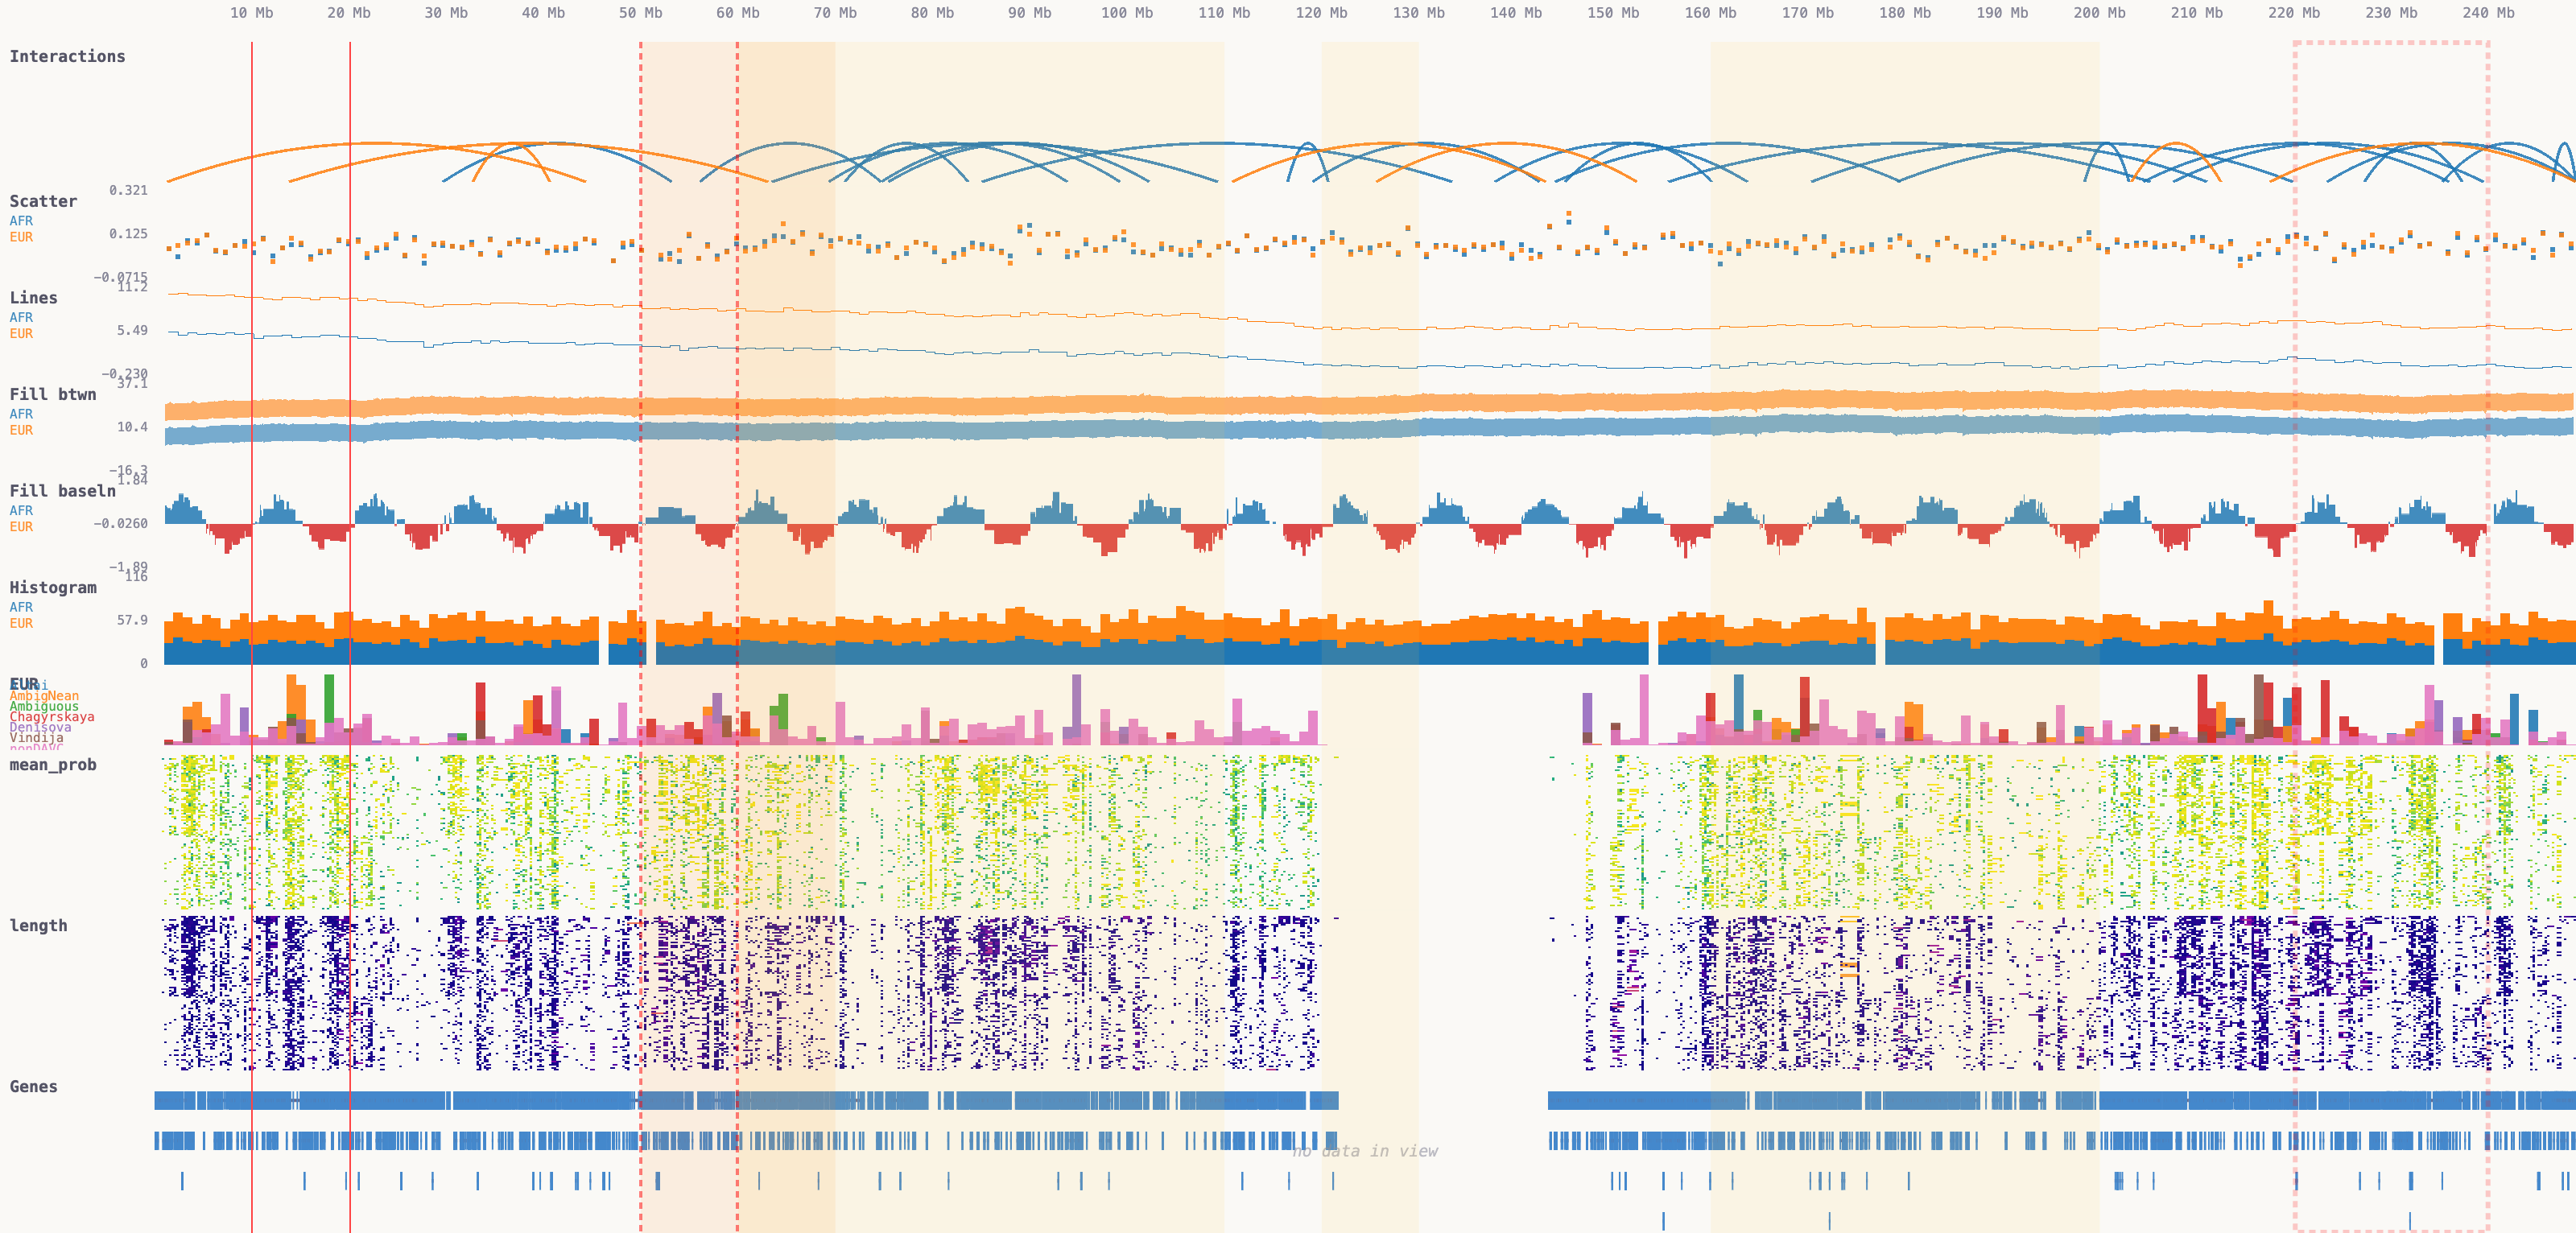

In [ ]:
tracks.clear_vlines()   

# dict style
tracks.add_vlines({'chr1': [50_000_000, 60_000_000], 'chr2': [3_000_000]}, color='red', alpha=0.5, linewidth=2, dash=[4, 3]) ;

# arg, kwarg style
tracks.add_vlines([10_000_000, 20_000_000], chrom='chr1', ) ;


You can add shaded regions/spans in similar way:

In [ ]:
tracks.clear_spans() 

# dict form: multiple chromosomes at once
tracks.add_spans({'chr1': [(160e6, 200e6)], 'chr2': [(5e6, 6e6)]}) ;

# elaborate styling
tracks.add_spans({'chr1': [(220e6, 240e6)], 'chr2': [(5e6, 6e6)]},
                    color='none', alpha=0.2,                                                          
                    edgecolor='red', edgewidth=3.0, 
                    dash=[4, 3]
                 ) ;  

# single span                                                                                          
tracks.add_spans((50_000_000, 70_000_000), chrom='chr1', color='C1') ;                                  
                                                                                                        
# multiple spans                                                                                       
tracks.add_spans([(60_000_000, 110_000_000), (120_000_000, 130_000_000)]) ;                                                                                                        

## Removing tracks

`Tracks` now has `remove_track(name_or_index)` and `clear_tracks()`:

- `remove_track('Scatter')` removes the single track named `'Scatter'`; raises `KeyError` if no track matches.
- `remove_track(0)` removes the first track by positional index.
- `clear_tracks()` drops every track (the viewer remains live and you can add new tracks to it).

Both return `self` so you can chain further updates, and both also release the track's GPU resources on the JS side, so re-running the same cell does not leak VRAM.

In [ ]:
# Build a viewer with two tracks, then remove one.
demo = (
    Tracks('hg38')
    .add_point_track(qdf, 'Scatter', x='pos', y='fst', group_by='pop', tip_fmt=False)
    .add_line_track (qdf, 'Lines',   x='pos', y='rate', group_by='pop', tip_fmt=False, step='post')
    .add_gene_track(height=100)
)
# Drop the line track by name and keep chaining:
demo.remove_track('Lines')
demo

In [ ]:
# Start over on the same viewer:
demo.clear_tracks().add_gene_track(height=60, highlight=['BRCA1', 'TP53'])
demo

## Programmatic zoom

Useful for setting some view you want to fix:

In [ ]:
tracks = (
    Tracks('hg38').add_point_track(
        qdf, 'GWAS -log10(p)', x='pos', y='fst', group_by='pop', tip_fmt=False,
    )
    .add_gene_track(label_padding=1000)
)

tracks.zoom_to('chr1', center=50_000_000, window=20_000_000)

## Panning movie

You can even make yourself a movie panning through a chromosome. You can also access the view coordinates to make it skip the centromere:

In [ ]:
from geneinfo.coords import centromere_coords
centr_coords = {c: (s, e) for c, s, e in centromere_coords('hg38')}
chrom_sizes = dict(chromosome_lengths(assembly='hg38'))

class Movie:
    def __init__(self, track, chrom, start=None, end=None, window=500_000):
        if start is None:
            start = 0
        if end is None:
            end = chrom_sizes[chrom]
        self.track = track
        self.chrom = chrom
        self.viewport = None
        self.start = start
        self.end = end
        self.window = window

    def __call__(self, *args, **kwds):        
        if self.viewport is not None:
            self.track.zoom_to(**self.viewport)
        else:
            self.track.zoom_to(chrom=self.chrom, start=self.start, end=self.end)
        try:
            centr_start, centr_end = centr_coords[chrom]
            for pos in range(self.start, self.end, 150):
                wp = tracks.viewport
                if wp['start'] > centr_start and wp['end'] < centr_end:
                    continue
                tracks.zoom_to(self.chrom, center=pos, window=self.window) ;
                sleep(0.005)
        except KeyboardInterrupt as e:
            self.viewport = self.track.viewport
            return        

movie = Movie(tracks, 'chrX')


In [ ]:
#movie()

## Tooltips

Each track contributes to the cursor tooltip unless `tip_fmt=False`. Use `tip_fmt` to control what each track contributes to the tooltip. Format placeholders use Python-style `{key}` or `{key:.Nf}` syntax.

Available keys per track type:
- **Gene**: `name`, `strand`, `start`, `end`
- **Scatter / Line**: `group`, `value`, `x`
- **Fill**: `group`, `lo`, `hi`, `x`
- **Histogram**: `group`, `value`, `x`
- **Segment**: `group`
- **Heatmap**: `group`, `individual`, `nInd`

If a format string references an invalid key, the tooltip shows the available keys as a hint.

In [ ]:
(
    Tracks(chrom_sizes)
    .add_point_track(
        qdf, 'Scatter', x='pos', y='fst', group_by='pop',
        tip_fmt="{value:.4f} is the value for {group}",
    )
    .add_line_track(
        qdf, 'Lines', x='pos', y='rate', group_by='pop',
        tip_fmt="For {group} the value is {value:.2f}",
    )
    .add_gene_track(
        assembly='hg38', height=44, 
        tip_fmt="The gene at this pos is {name}",
    )
)

## Theme

The widget has a light and dark default theme determined by the vscodenb package if installed. You get the active theme defaults like this:

In [ ]:
from geneinfo.widget import Tracks
from geneinfo.widget import get_default_theme, set_default_theme
theme = get_default_theme()
theme

You can change the theme colors and save them back for use in subsequent viewers. As of the latest release, assigning a **partial** theme dict merges onto the current theme (rather than replacing it), and passing an unknown key raises `TraitError` so typos surface immediately:

```python
v = Tracks('hg38').add_gene_track()
v.theme = {'bg': '#202030'}   # only overrides 'bg'; every other key is preserved
# v.theme = {'bogus': '#fff'}   # would raise TraitError
```

In [ ]:
# theme['input_bg'] = 'pink'
set_default_theme(theme)

## Using with `geneinfo`'s rewamped UCSC track support

In [ ]:
from geneinfo.widget import Tracks
import pandas as pd

from geneinfo import ucsc

In [ ]:
from geneinfo import ucsc
df = ucsc.get_track('gnomadConstraint', 'hg38',                               
                    chrom='chr1', start=10_000_000, end=15_000_000)           
                                                                            
ucsc.list_subtracks('dbSnp155Composite', 'hg38')                              

### Discover / search tracks

List everything for hg38 (long — pipe to a pager or filter first)

In [ ]:
ucsc.search_tracks(assembly='hg38')

Fuzzy search                                                                

In [ ]:
ucsc.search_tracks('lrSV', assembly='hg38')

In [ ]:
ucsc.search_tracks('gnomad constraint', assembly='hg38')

In [ ]:
ucsc.search_tracks('decode', assembly='hg38')

In [ ]:
ucsc.search_tracks('recombination rate', assembly='hg38')

In [ ]:
ucsc.search_tracks('gtex', assembly='hg38')

Inspect a single track's metadata (type, longLabel, bigDataUrl, ...)

In [ ]:
ucsc.get_track_meta('gnomadConstraint', assembly='hg38')

In [ ]:
ucsc.get_track_meta('decodeSv', assembly='hg38')

In [ ]:
ucsc.get_track_meta('lrSvAll', assembly='hg38')

In [ ]:
df = ucsc.get_track(f'lrSvAll', chrom='chr1', 
#                    start=10_000_000, end=11_000_000, 
                    assembly='hg38')  
df

In [ ]:
ucsc.track_info(f'lrSvAll', assembly='hg38')

In [ ]:
df = ucsc.get_track(f'recombAvg', chrom='chr1', 
#                    start=10_000_000, end=11_000_000, 
                    assembly='hg38')  
df

In [ ]:
df = ucsc.get_track(f'decodeSv', chrom='chr1', 
#                    start=10_000_000, end=11_000_000, 
                    assembly='hg38')  
df

In [ ]:
df_list = []
for base in ['A', 'T', 'G', 'C']:
    df = ucsc.get_track(f'alphaMissense_{base}', chrom='chrX', 
                        # start=10_000_000, end=11_000_000, 
                        assembly='hg38')  
    df['base'] = base                                                                              
    df_list.append(df)
alphaMissense = pd.concat(df_list)
#df.to_parquet('~/alphaMissense.parquet')       
alphaMissense.tail()

|  n   | binWidth_bp | binWidth_px at full-chrom view |
| ---- | ----------- | ------------------------------ |
| 64   |      3.9 Mb |                        15.6 px |
| 256  |      970 kb |                         3.9 px |
| 1024 |      243 kb |                        0.98 px |
| 4096 |       61 kb |                        0.24 px |

In [ ]:
# 1. Default LOD — (256, 1024, 4096) bins per chromosome                      
Tracks('hg38').add_ucsc_track('gnomadConstraint', chrom='chrX', kind='line').zoom_to('chrX')                                                                             

In [ ]:
# 4. Disable LOD entirely — ship every sample at every zoom                   
Tracks('hg38').add_ucsc_track(                                                
    'gnomadConstraint', chrom='chrX', kind='line',                          
    density_windows=(),
    ).zoom_to('chrX')    

In [ ]:
Tracks('hg38').add_ucsc_track('gnomadConstraint', chrom='chrX', kind='point').zoom_to('chrX')   


In [ ]:

Tracks('hg38').add_ucsc_track('gnomadConstraint', kind='point', chrom='chrX', value_col='value', palette='viridis').zoom_to('chrX')


In [ ]:
Tracks('hg38').add_ucsc_track('recombAvg', chrom='chr1', kind='fill', zoom_windows=(64, 256, 1024)).zoom_to('chr1')   
#Tracks('hg38').add_ucsc_track('recombAvg', chrom='chr1', kind='line', y_scale='log', zoom_windows=(64, 256, 1024)).zoom_to('chr1')   

In [ ]:
(Tracks('hg38')
    .add_ucsc_track('lrSvAll', chrom='chrX', kind='segment', group_by='svType', height=100, tip_fmt=False)#, stack=True)  
    .add_ucsc_track('lrSvAll', chrom='chrX', kind='heatmap', group_by='svType', height=150, tip_fmt=False)
).zoom_to('chrX')  

In [ ]:
df = ucsc.get_track(f'lrSvAll', chrom='chrX', assembly='hg38')  
df

In [ ]:
(Tracks('hg38')
    .clear_spans().add_spans(ECH_regions, color='magenta')
    .clear_vlines().add_vlines(gene_pos)
    .add_segment_track(df.loc[df.svType.isin(['INV', 'DUP', 'CPX'])], "Density", group_by="svType", height=150, stack=True)
#    .add_heatmap_track(df.loc[df.svType.isin(['INV', 'DUP', 'CPX'])], "Density", group_by="svType")
    .add_gene_track()
).zoom_to('chrX')  

# (Tracks('hg38')
#     .add_ucsc_track('lrSvAll', chrom='chrX', kind='segment', group_by='svType', height=100, tip_fmt=False)#, stack=True)  
#     .add_ucsc_track('lrSvAll', chrom='chrX', kind='heatmap', group_by='svType', height=150, tip_fmt=False)


In [ ]:
tracks = (
    Tracks('hg38')
    .add_ucsc_track('recombAvg', kind='line', chrom='chrX', color='C0')
    .add_ucsc_track('gnomadConstraint', kind='point', chrom='chrX')
    .add_ucsc_track('gtexCovBrainCortex', chrom='chrX', color='C1')
    .add_ucsc_track('gtexCovTestis', chrom='chrX', color='C2')
    .add_ucsc_track('gtexTranscExpr', kind='point', chrom='chrX', color='C3')
    .add_point_track(alphaMissense, 'alphaMissense', x='start', y='value', value_col='base')
    .add_heatmap_track(
        segments, "mean_prob",
        individual_col="ind",
        value_col="mean_prob",
        palette="viridis",
        vmin=0.0, vmax=1.0,
    ).add_heatmap_track(
        segments, "length",
        individual_col="ind",
        value_col="length",
        palette='plasma',
    ).add_gene_track()
).zoom_to('chrX') 


In [ ]:

tracks.add_vlines({'chr1': [50_000_000, 60_000_000], 'chr2': [3_000_000]}, color='red', alpha=0.5, linewidth=2, dash=[4, 3]) ;
tracks.add_spans({'chr1': [(220e6, 240e6)], 'chr2': [(5e6, 6e6)]},
                    color='none', alpha=0.2,                                                          
                    edgecolor='red', edgewidth=3.0, 
                    dash=[4, 3]
                 ) ;                                                                                                          
tracks.add_spans([(60_000_000, 110_000_000), (120_000_000, 130_000_000)]) 
tracks  


# Try to make a alphaMissense/cons30way or something track to find regions unconserved dispite being pathogenic

# iPlot

make sure variables are taken from OPTIONS:

```python
OPTIONS = dict(
    default_height=5,
    max_figure_width=10, 
    max_figure_height=5,
    max_facet_height = 3
    min_facet_height = 2
    theme = dict(style='darkgrid', palette='viridis'),
    graphics=AXIS_LEVEL_GRAPHICS
    )

max_facet_height = OPTIONS['max_facet_height']
min_facet_height = OPTIONS['min_facet_height']
default_height = OPTIONS['default_height']
```

In [ ]:
import iplot
import importlib
importlib.reload(iplot)
#iplot.iplot_settings(default_height=1)

In [ ]:
iplot.iplot_settings(max_facet_height=1.5, min_facet_height=1, default_height=2)
import matplotlib
matplotlib.rcdefaults()
matplotlib.rc('font', size=4)
iplot.iplot(segments)

rc = {'font.size': 4}
with matplotlib.rc_context(rc):
    print(matplotlib.rcParams)
    iplot.iplot(segments)

In [ ]:
f'{segments=}'.split('=')[0]

In [ ]:
matplotlib.rc_params().get('font.size')

In [ ]:
matplotlib.rc('font', size=4)

In [ ]:
data = segments
import seaborn as sns
sns.set_style({'style': 'darkgrid', 'palette': 'viridis'})                             
g = sns.displot(data, x='chrom', height=4, kind='hist')
g.set_titles(col_template="{col_name}", row_template="{row_name}")
g.tight_layout()

# upgrade vscode to get to return the background color

In [ ]:
import matplotlib.pyplot as plt
from geneinfo.plot import upset
from vscodenb import set_vscode_theme, is_vscode_dark_theme
set_vscode_theme()
is_vscode_dark_theme()  

In [ ]:
from geneinfo.genelist import GeneList as glist
from geneinfo.genelist import GeneListCollection
sheet = GeneListCollection(google_sheet='1JSjSLuto3jqdEnnG7JqzeC_1pUZw76n7XueVAYrUOpk')

In [ ]:
upset({
    'A': set(sheet.get('cDEG')), 
    'B': set(sheet.get('nDEG'))
    })

In [ ]:
cDEG = sheet.get('cDEG')
cDEG

In [ ]:
upset([
    sheet.get('cDEG'), 
    sheet.get('nDEG')
    ])